# 2. Evaluation and calibration of BDI + character n-grams — hexameters, cross-work design

This notebook replaces the previous same-author calibration with a stricter **cross-work** design.

The purpose is to calibrate the verifier on the same type of problem faced in attribution:
a target segment from one work is compared with candidate material by the same author drawn from a **different work**.

Main rules:

- the four uncertain texts remain complete holdouts;
- known texts are split into contiguous, non-overlapping 750-token chunks;
- the existing approximately 70/30 split by work is preserved;
- *same-author* calibration problems are built only from authors represented by at least two distinct works in the training split;
- Q comes from one work and candidate material is restricted to another work by the same author;
- *different-author* Q is sampled from the same cross-work-eligible author population;
- single-work authors remain available as impostors and as wrong candidates;
- all other character n-gram and BDI parameters remain unchanged, so this notebook isolates the effect of the calibration redesign.

A lower accuracy than in the previous calibration is not automatically a failure: the cross-work task is intentionally harder and more closely matches the actual attribution problem.

In [2]:
from __future__ import annotations

from pathlib import Path
import sys
import json
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import joblib

## 1. Directories and parameters

In [4]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()

    for folder in [current, *current.parents]:
        if (
            (folder / "data_processed").is_dir()
            and (folder / "ruzicka").is_dir()
        ):
            return folder

    raise FileNotFoundError(
        "Could not find the project directory containing both "
        "'data_processed' and 'ruzicka'."
    )


PROJECT_DIR = find_project_root()
PROCESSED_DIR = PROJECT_DIR / "data_processed"
OUTPUT_DIR = PROJECT_DIR / "results_bdi_ngrams_hexameters_crosswork"
OUTPUT_DIR.mkdir(exist_ok=True)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from ruzicka.BDIVerifier import BDIVerifier

logging.getLogger("ruzicka").setLevel(logging.WARNING)

# Corpus and split
TRAIN_PCT = 0.70
SAMPLE_TOKENS = 750

# Keep two candidate chunks per problem, as in the elegiac workflow.
KNOWN_SAMPLES = 2

# Keep approximately 20,000 reference tokens.
REFERENCE_TOKENS_TARGET = 20_000
REFERENCE_SAMPLES = round(REFERENCE_TOKENS_TARGET / SAMPLE_TOKENS)  # 27 = 20,250 tokens

# Character n-grams + BDI
NGRAM_RANGE = (3, 5)
MAX_FEATURES = 10_000
N_BOOTSTRAP = 1000
RND_PROP = 0.33

# Calibration
N_SAME_AUTHOR = 400
N_DIFFERENT_AUTHOR = 400

SPLIT_SEED = 42
CALIBRATION_SEED = 42

EXPECTED_HOLDOUTS = {
    "X_ordine.txt",
    "X2_ecclesiastes.txt",
    "X3_machabeis.txt",
    "X4_certamina.txt",
}

print(f"Project:          {PROJECT_DIR}")
print(f"Processed data:   {PROCESSED_DIR}")
print(f"Output:           {OUTPUT_DIR}")
print(f"Sample tokens:    {SAMPLE_TOKENS}")
print(f"Candidate chunks: {KNOWN_SAMPLES} ({KNOWN_SAMPLES * SAMPLE_TOKENS} tokens)")
print(
    f"Reference chunks: {REFERENCE_SAMPLES} "
    f"(~{REFERENCE_SAMPLES * SAMPLE_TOKENS} tokens)"
)
print(f"N-grams:          {NGRAM_RANGE}")

Project:          /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Lexical analysis
Processed data:   /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Lexical analysis/data_processed
Output:           /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Lexical analysis/results_bdi_ngrams_hexameters_crosswork
Sample tokens:    750
Candidate chunks: 2 (1500 tokens)
Reference chunks: 27 (~20250 tokens)
N-grams:          (3, 5)


## 2. Loading processed texts

In [6]:
manifest_path = PROCESSED_DIR / "manifest.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Could not find {manifest_path}. Run notebook 1 first."
    )

manifest = pd.read_csv(manifest_path)

required = {"file", "author", "work", "holdout", "tokens"}
missing = required - set(manifest.columns)

if missing:
    raise ValueError(f"Missing columns in manifest: {sorted(missing)}")

if manifest["holdout"].dtype != bool:
    manifest["holdout"] = (
        manifest["holdout"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False})
    )

actual_holdouts = set(
    manifest.loc[manifest["holdout"], "file"].tolist()
)

missing_holdouts = sorted(EXPECTED_HOLDOUTS - actual_holdouts)
unexpected_holdouts = sorted(actual_holdouts - EXPECTED_HOLDOUTS)

if missing_holdouts:
    raise ValueError(
        "Expected holdout files missing from manifest: "
        + ", ".join(missing_holdouts)
    )

if unexpected_holdouts:
    print(
        "WARNING: additional holdout files found in manifest:",
        unexpected_holdouts,
    )

texts_by_file = {}

for row in manifest.itertuples(index=False):
    path = PROCESSED_DIR / row.file

    if not path.exists():
        raise FileNotFoundError(
            f"File listed in manifest not found: {path}"
        )

    texts_by_file[row.file] = path.read_text(
        encoding="utf-8"
    ).strip()

print(f"Files in manifest:   {len(manifest)}")
print(f"Known-author files:  {(~manifest['holdout']).sum()}")
print(f"Holdout files:       {manifest['holdout'].sum()}")

display(
    manifest.loc[
        manifest["holdout"],
        ["file", "author", "work", "tokens"],
    ]
)

Files in manifest:   47
Known-author files:  43
Holdout files:       4


,file,author,work,tokens
43,X_ordine.txt,X,ordine,3625
44,X2_ecclesiastes.txt,X2,ecclesiastes,958
45,X3_machabeis.txt,X3,machabeis,3085
46,X4_certamina.txt,X4,certamina,1002


## 3. Chunking known-author texts only

Each known work is divided into contiguous, non-overlapping 750-token chunks.
Final remainders shorter than 750 tokens are discarded.

In [8]:
def make_full_chunks(
    text: str,
    sample_tokens: int = SAMPLE_TOKENS,
) -> list[str]:
    tokens = text.split()
    n_full = len(tokens) // sample_tokens

    return [
        " ".join(
            tokens[
                i * sample_tokens : (i + 1) * sample_tokens
            ]
        )
        for i in range(n_full)
    ]


chunk_records = []

for row in manifest.loc[
    ~manifest["holdout"]
].itertuples(index=False):

    chunks = make_full_chunks(
        texts_by_file[row.file]
    )

    if not chunks:
        print(
            f"WARNING: {row.file} has fewer than "
            f"{SAMPLE_TOKENS} tokens and produces no full chunks."
        )
        continue

    for chunk_number, chunk in enumerate(chunks):
        chunk_records.append(
            {
                "author": row.author,
                "work": row.work,
                "file": row.file,
                "chunk_number": chunk_number,
                "tag": (
                    f"{row.author}_{row.work}_{chunk_number}"
                ),
                "chunk": chunk,
                "tokens": len(chunk.split()),
            }
        )

known_chunks = pd.DataFrame(chunk_records)

if known_chunks.empty:
    raise ValueError(
        "No full chunks were produced from known-author texts."
    )

print(
    f"Known-author complete chunks: {len(known_chunks)}"
)

display(
    known_chunks.groupby(["author", "work"])
    .size()
    .rename("n_chunks")
    .reset_index()
)

Known-author complete chunks: 915


,author,work,n_chunks
0,AI,anticlaudianus,37
1,AeC,medicaminum,36
2,AeC,viaticus,18
3,AeP,karolinus,22
4,B,judas,7
5,BC,contemptu,28
6,DC,mathildis,25
7,E,biblia,12
8,FB,nuptis,42
9,GAp,roberti,22


## 4. 70/30 split by work

In [10]:
def split_chunks_by_work(
    chunks_df: pd.DataFrame,
    train_pct: float = TRAIN_PCT,
    seed: int = SPLIT_SEED,
) -> tuple[pd.DataFrame, pd.DataFrame]:

    rng = np.random.default_rng(seed)
    train_parts = []
    test_parts = []

    for (author, work), group in chunks_df.groupby(
        ["author", "work"],
        sort=True,
    ):
        indices = group.index.to_numpy(copy=True)
        rng.shuffle(indices)

        n = len(indices)

        if n == 1:
            train_idx = indices
            test_idx = np.array([], dtype=int)

            print(
                f"WARNING: {author}_{work} has only one "
                "full chunk; assigned to training only."
            )
        else:
            n_train = int(round(n * train_pct))
            n_train = max(
                1,
                min(n - 1, n_train),
            )

            train_idx = indices[:n_train]
            test_idx = indices[n_train:]

        train_parts.append(
            chunks_df.loc[train_idx]
        )

        if len(test_idx):
            test_parts.append(
                chunks_df.loc[test_idx]
            )

    train_df = pd.concat(
        train_parts,
        ignore_index=True,
    )

    test_df = (
        pd.concat(
            test_parts,
            ignore_index=True,
        )
        if test_parts
        else pd.DataFrame(
            columns=chunks_df.columns
        )
    )

    return train_df, test_df


train_df, test_df = split_chunks_by_work(
    known_chunks
)

print(f"Train chunks: {len(train_df)}")
print(f"Test chunks:  {len(test_df)}")
print(
    f"Train tokens: {train_df['tokens'].sum():,}"
)
print(
    f"Test tokens:  {test_df['tokens'].sum():,}"
)

split_summary = (
    pd.concat(
        [
            train_df.assign(split="train"),
            test_df.assign(split="test"),
        ]
    )
    .groupby(
        ["author", "work", "split"]
    )
    .size()
    .unstack(fill_value=0)
)

display(split_summary)

train_df.to_csv(
    OUTPUT_DIR
    / "ngrams_hexameters_train_chunks.csv",
    index=False,
)

test_df.to_csv(
    OUTPUT_DIR
    / "ngrams_hexameters_test_chunks.csv",
    index=False,
)

split_summary.to_csv(
    OUTPUT_DIR
    / "ngrams_hexameters_split_summary.csv"
)

Train chunks: 639
Test chunks:  276
Train tokens: 479,250
Test tokens:  207,000


split                  test  train
author work                       
AI     anticlaudianus    11     26
AeC    medicaminum       11     25
       viaticus           5     13
AeP    karolinus          7     15
B      judas              2      5
BC     contemptu          8     20
DC     mathildis          7     18
E      biblia             4      8
FB     nuptis            13     29
GAp    roberti            7     15
GAr    philippis         13     30
GC     alexandreis       14     31
GM     merlini            4      8
GP     ligurinus         16     37
GVS    poetria            6     13
GiP    historia           6     15
H      epigrammata        1      2
       maria              2      5
HA     planctus           6     14
HP     maiolichinus       8     20
IH     architrenius      11     24
II     ylias              9     21
M      capitulorum        3      8
       maurilii           1      4
       victoris           1      3
NLC    passio             6     14
OM     ernestus           9     20
OSE    doctrina           5     10
RC     tancredi           2      6
RT     mauri              2      5
SG     ecclesiasten       1      1
U1     canticamariae      1      1
U10    karolellus         5     11
U11    katherinae         9     20
U2     liberesdre         1      2
U3     generatione        4      9
U4     dialogi           17     41
U5     britanniae        12     28
       brutus             1      4
U6     roudlieb           6     13
U7     flosmedicinae      5     12
U8     friderici          8     19
U9     vetula             6     14

## 5. Cross-work eligibility checks

An author is eligible for positive calibration problems only if the training split contains at least two distinct works.

The same eligible Q-author population is used for both positive and negative calibration problems, so class membership is not confounded with a different set of Q authors.

In [12]:
train_author_counts = (
    train_df.groupby("author")
    .size()
    .sort_values()
)

test_author_counts = (
    test_df.groupby("author")
    .size()
    .sort_values()
)

author_work_counts = (
    train_df.groupby(["author", "work"])
    .size()
    .rename("n_chunks")
    .reset_index()
)

works_per_author = (
    author_work_counts.groupby("author")["work"]
    .nunique()
    .sort_values(ascending=False)
)

crosswork_authors = sorted(
    works_per_author[
        works_per_author >= 2
    ].index.tolist()
)

all_train_authors = sorted(
    train_author_counts.index.tolist()
)

print("Train chunks by author:")
display(
    train_author_counts
    .rename("n_chunks")
    .to_frame()
)

print("Test chunks by author:")
display(
    test_author_counts
    .rename("n_chunks")
    .to_frame()
)

print("\nCross-work eligible authors:")
print(crosswork_authors)

print(
    f"Eligible authors: {len(crosswork_authors)} / "
    f"{len(all_train_authors)} total training authors"
)

display(
    author_work_counts[
        author_work_counts["author"].isin(crosswork_authors)
    ].sort_values(["author", "work"])
)

if len(crosswork_authors) < 2:
    raise RuntimeError(
        "Fewer than two authors have at least two distinct works "
        "in the training split. A meaningful cross-work calibration "
        "cannot be built."
    )

Train chunks by author:


,n_chunks
author,
SG,1
U1,1
U2,2
B,5
RT,5
RC,6
H,7
E,8
GM,8


Test chunks by author:


,n_chunks
author,
SG,1
U2,1
U1,1
B,2
RT,2
RC,2
H,3
E,4
U3,4



Cross-work eligible authors:
['AeC', 'H', 'M', 'U5']
Eligible authors: 4 / 38 total training authors


,author,work,n_chunks
1,AeC,medicaminum,25
2,AeC,viaticus,13
16,H,epigrammata,2
17,H,maria,5
22,M,capitulorum,8
23,M,maurilii,4
24,M,victoris,3
37,U5,britanniae,28
38,U5,brutus,4


## 6. BDI functions

Candidate and impostor pools are kept logically separate.

This is important for the later application notebooks: another text of uncertain authorship can be introduced as a **candidate** without automatically entering the **impostor** pool.

TF-IDF and scaling are fitted exclusively on the comparison set for each problem. Q is transformed only.

In [14]:
def balanced_reference_sample(
    ref_pool: pd.DataFrame,
    n_samples: int,
    rng: np.random.Generator,
) -> pd.DataFrame:

    if len(ref_pool) <= n_samples:
        return ref_pool.copy()

    selected_indices = []

    available_by_author = {
        author: group.index.to_list()
        for author, group
        in ref_pool.groupby("author")
    }

    for author in available_by_author:
        rng.shuffle(
            available_by_author[author]
        )

    authors = list(
        available_by_author
    )

    while len(selected_indices) < n_samples:
        rng.shuffle(authors)
        added_this_round = 0

        for author in authors:
            if available_by_author[author]:
                selected_indices.append(
                    available_by_author[
                        author
                    ].pop()
                )

                added_this_round += 1

                if len(
                    selected_indices
                ) >= n_samples:
                    break

        if added_this_round == 0:
            break

    return ref_pool.loc[
        selected_indices
    ].copy()


def build_comparison_sample(
    candidate_pool: pd.DataFrame,
    reference_pool: pd.DataFrame,
    candidate_author: str,
    rng: np.random.Generator,
    known_samples: int = KNOWN_SAMPLES,
    reference_samples: int = REFERENCE_SAMPLES,
) -> pd.DataFrame:

    candidate_rows = candidate_pool[
        candidate_pool["author"]
        == candidate_author
    ]

    reference_rows = reference_pool[
        reference_pool["author"]
        != candidate_author
    ]

    if candidate_rows.empty:
        raise ValueError(
            f"No samples available for candidate "
            f"{candidate_author!r}."
        )

    if reference_rows.empty:
        raise ValueError(
            "No impostor samples available."
        )

    # Preserve the existing workflow:
    # if fewer candidate samples are available,
    # use all available samples.
    n_known = min(
        known_samples,
        len(candidate_rows),
    )

    candidate_idx = rng.choice(
        candidate_rows.index.to_numpy(),
        size=n_known,
        replace=False,
    )

    candidate_part = (
        candidate_rows.loc[
            candidate_idx
        ].copy()
    )

    reference_part = (
        balanced_reference_sample(
            reference_rows,
            min(
                reference_samples,
                len(reference_rows),
            ),
            rng,
        )
    )

    return pd.concat(
        [
            candidate_part,
            reference_part,
        ],
        ignore_index=True,
    )


def vectorize_problem(
    comparison_df: pd.DataFrame,
    q_text: str,
):
    vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=NGRAM_RANGE,
        use_idf=True,
        norm="l2",
        max_features=MAX_FEATURES,
        lowercase=False,
        decode_error="replace",
    )

    X_comp_sparse = (
        vectorizer.fit_transform(
            comparison_df["chunk"]
        )
    )

    X_q_sparse = (
        vectorizer.transform(
            [q_text]
        )
    )

    scaler = StandardScaler(
        with_mean=False
    )

    X_comp = (
        scaler.fit_transform(
            X_comp_sparse
        ).toarray()
    )

    X_q = (
        scaler.transform(
            X_q_sparse
        ).toarray()
    )

    return (
        X_comp,
        X_q,
        vectorizer,
    )


def run_bdi_problem(
    q_text: str,
    candidate_pool: pd.DataFrame,
    reference_pool: pd.DataFrame,
    candidate_author: str,
    seed: int,
    return_distances: bool = False,
) -> dict:

    rng = np.random.default_rng(
        seed
    )

    comparison_df = (
        build_comparison_sample(
            candidate_pool=candidate_pool,
            reference_pool=reference_pool,
            candidate_author=candidate_author,
            rng=rng,
        )
    )

    (
        X_comp,
        X_q,
        vectorizer,
    ) = vectorize_problem(
        comparison_df,
        q_text,
    )

    label_encoder = LabelEncoder()

    y_comp = (
        label_encoder.fit_transform(
            comparison_df["author"]
        )
    )

    if candidate_author not in set(
        label_encoder.classes_
    ):
        raise ValueError(
            f"The candidate "
            f"{candidate_author!r} "
            "is not present in the "
            "comparison set."
        )

    candidate_label = int(
        label_encoder.transform(
            [candidate_author]
        )[0]
    )

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=N_BOOTSTRAP,
        rnd_prop=RND_PROP,
        random_state=np.random.default_rng(
            seed
        ),
    )

    verifier.fit(
        X_comp,
        y_comp,
    )

    # Use all impostors available in the deliberately
    # limited comparison set.
    match = verifier.predict_proba(
        X_q,
        [candidate_label],
        nb_imposters=0,
    )

    match_strength = float(
        np.asarray(
            match
        ).reshape(-1)[0]
    )

    result = {
        "match_strength": (
            match_strength
        ),
        "candidate_samples_used": int(
            (
                comparison_df["author"]
                == candidate_author
            ).sum()
        ),
        "reference_samples_used": int(
            (
                comparison_df["author"]
                != candidate_author
            ).sum()
        ),
        "n_features": len(
            vectorizer
            .get_feature_names_out()
        ),
    }

    if return_distances:
        dist = getattr(
            verifier,
            "_dist_arrays",
            None,
        )

        if dist is not None:
            try:
                result[
                    "distances"
                ] = np.asarray(
                    dist[0],
                    dtype=float,
                )
            except Exception:
                result[
                    "distances"
                ] = np.asarray(
                    dist,
                    dtype=float,
                ).reshape(-1)

    return result

## 7. Preparing the 400 + 400 cross-work calibration problems

For *same-author* problems:

1. choose an eligible author uniformly;
2. choose one of that author's works uniformly as the Q work;
3. choose one Q chunk from that work;
4. remove every remaining chunk from that same work by that author from the candidate pool;
5. candidate material can therefore come only from a different work by the same author.

For *different-author* problems, Q is drawn from the same cross-work-eligible author population, while the wrong candidate is sampled uniformly from all other training authors.

In [16]:
master_rng = np.random.default_rng(
    CALIBRATION_SEED
)

calibration_specs = []

# 400 SAME-AUTHOR, CROSS-WORK problems
for _ in range(N_SAME_AUTHOR):

    q_author = str(
        master_rng.choice(
            crosswork_authors
        )
    )

    author_rows = train_df[
        train_df["author"] == q_author
    ]

    q_works = sorted(
        author_rows["work"]
        .unique()
        .tolist()
    )

    q_work = str(
        master_rng.choice(q_works)
    )

    q_candidates = author_rows[
        author_rows["work"] == q_work
    ]

    q_idx = int(
        master_rng.choice(
            q_candidates.index.to_numpy()
        )
    )

    q_row = train_df.loc[q_idx]

    base_pool = train_df.drop(
        index=q_idx
    ).copy()

    # For the positive candidate, remove all remaining chunks
    # from the same work as Q. This forces a cross-work comparison.
    candidate_pool = base_pool[
        ~(
            (base_pool["author"] == q_author)
            & (base_pool["work"] == q_work)
        )
    ].reset_index(drop=True)

    reference_pool = base_pool.reset_index(
        drop=True
    )

    candidate_works_allowed = sorted(
        candidate_pool.loc[
            candidate_pool["author"] == q_author,
            "work",
        ]
        .unique()
        .tolist()
    )

    if not candidate_works_allowed:
        raise RuntimeError(
            f"No cross-work candidate material remains for {q_author}."
        )

    calibration_specs.append(
        {
            "type": "same",
            "q_tag": q_row["tag"],
            "q_author": q_author,
            "q_work": q_work,
            "candidate_author": q_author,
            "candidate_works_allowed": "|".join(
                candidate_works_allowed
            ),
            "q_text": q_row["chunk"],
            "candidate_pool": candidate_pool,
            "reference_pool": reference_pool,
            "seed": int(
                master_rng.integers(
                    0,
                    2**32 - 1,
                )
            ),
        }
    )


# 400 DIFFERENT-AUTHOR problems
# Q comes from the same cross-work-eligible author population.
for _ in range(N_DIFFERENT_AUTHOR):

    q_author = str(
        master_rng.choice(
            crosswork_authors
        )
    )

    author_rows = train_df[
        train_df["author"] == q_author
    ]

    q_work = str(
        master_rng.choice(
            sorted(
                author_rows["work"]
                .unique()
                .tolist()
            )
        )
    )

    q_candidates = author_rows[
        author_rows["work"] == q_work
    ]

    q_idx = int(
        master_rng.choice(
            q_candidates.index.to_numpy()
        )
    )

    q_row = train_df.loc[q_idx]

    wrong_authors = [
        author
        for author in all_train_authors
        if author != q_author
    ]

    candidate_author = str(
        master_rng.choice(
            wrong_authors
        )
    )

    pool = train_df.drop(
        index=q_idx
    ).reset_index(drop=True)

    calibration_specs.append(
        {
            "type": "different",
            "q_tag": q_row["tag"],
            "q_author": q_author,
            "q_work": q_work,
            "candidate_author": candidate_author,
            "candidate_works_allowed": "not_applicable",
            "q_text": q_row["chunk"],
            "candidate_pool": pool,
            "reference_pool": pool,
            "seed": int(
                master_rng.integers(
                    0,
                    2**32 - 1,
                )
            ),
        }
    )


specs_df = pd.DataFrame(
    [
        {
            key: value
            for key, value in spec.items()
            if key not in {
                "q_text",
                "candidate_pool",
                "reference_pool",
            }
        }
        for spec in calibration_specs
    ]
)

print(
    f"Calibration problems: {len(calibration_specs)}"
)

print(
    specs_df["type"].value_counts()
)

print("\nQ-author distribution by class:")

display(
    pd.crosstab(
        specs_df["q_author"],
        specs_df["type"],
    )
)

specs_df.to_csv(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_calibration_specs.csv",
    index=False,
)

Calibration problems: 800
type
same         400
different    400
Name: count, dtype: int64

Q-author distribution by class:


type,different,same
q_author,,
AeC,101,90
H,106,95
M,88,105
U5,105,110


## 8. Running cross-work calibration

In [18]:
calibration_results = []

for spec in tqdm(
    calibration_specs,
    desc="Cross-work BDI n-gram calibration",
):
    try:
        result = run_bdi_problem(
            q_text=spec["q_text"],
            candidate_pool=spec["candidate_pool"],
            reference_pool=spec["reference_pool"],
            candidate_author=spec["candidate_author"],
            seed=spec["seed"],
        )

        calibration_results.append(
            {
                "type": spec["type"],
                "q_tag": spec["q_tag"],
                "q_author": spec["q_author"],
                "q_work": spec["q_work"],
                "candidate_author": spec["candidate_author"],
                "candidate_works_allowed": spec[
                    "candidate_works_allowed"
                ],
                **result,
                "error": None,
            }
        )

    except Exception as exc:
        calibration_results.append(
            {
                "type": spec["type"],
                "q_tag": spec["q_tag"],
                "q_author": spec["q_author"],
                "q_work": spec["q_work"],
                "candidate_author": spec["candidate_author"],
                "candidate_works_allowed": spec[
                    "candidate_works_allowed"
                ],
                "match_strength": np.nan,
                "candidate_samples_used": np.nan,
                "reference_samples_used": np.nan,
                "n_features": np.nan,
                "error": repr(exc),
            }
        )

calibration_df = pd.DataFrame(
    calibration_results
)

calibration_df.to_csv(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_calibration_results.csv",
    index=False,
)

valid_calibration = (
    calibration_df[
        calibration_df["error"].isna()
    ]
    .copy()
)

print(f"Completed: {len(calibration_df)}")
print(f"Valid:     {len(valid_calibration)}")
print(
    "Errors:    "
    f"{calibration_df['error'].notna().sum()}"
)

if calibration_df["error"].notna().any():
    display(
        calibration_df.loc[
            calibration_df["error"].notna(),
            [
                "type",
                "q_tag",
                "q_author",
                "q_work",
                "candidate_author",
                "error",
            ],
        ].head(30)
    )

Cross-work BDI n-gram calibration:   0%|          | 0/800 [00:00<?, ?it/s]

Completed: 800
Valid:     800
Errors:    0


In [19]:
# Fail early with the real BDI errors if calibration
# produced no valid problems.
if len(valid_calibration) == 0:
    unique_errors = (
        calibration_df["error"]
        .dropna()
        .value_counts()
        .head(10)
    )

    print(
        "\nNo valid calibration problems "
        "were produced."
    )

    print(
        "Most frequent BDI errors:"
    )

    display(
        unique_errors
        .rename("count")
        .to_frame()
    )

    raise RuntimeError(
        "Calibration produced 0 valid "
        "BDI problems. Inspect the errors "
        "shown above before fitting "
        "logistic regression."
    )

class_counts = (
    valid_calibration["type"]
    .value_counts()
)

if not {
    "same",
    "different",
}.issubset(
    class_counts.index
):
    raise RuntimeError(
        "Calibration does not contain "
        "both classes: "
        f"{class_counts.to_dict()}"
    )

print(
    "\nCalibration data are valid "
    "for logistic regression."
)

print(class_counts)


Calibration data are valid for logistic regression.
type
same         400
different    400
Name: count, dtype: int64


## 9. Match-strength distribution

In [21]:
display(
    valid_calibration
    .groupby("type")[
        "match_strength"
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
)

,count,mean,std,median,min,max
type,,,,,,
different,400,0.026235,0.115812,0.000,0.0,1.0
same,400,0.213438,0.368695,0.001,0.0,1.0


## 10. Logistic regression and performance in the calibration sample

In [23]:
valid_calibration[
    "match_strength"
] = pd.to_numeric(
    valid_calibration[
        "match_strength"
    ],
    errors="coerce",
)

valid_calibration = (
    valid_calibration
    .dropna(
        subset=[
            "match_strength",
            "type",
        ]
    )
    .reset_index(drop=True)
)

y = (
    valid_calibration["type"]
    == "same"
).astype(int).to_numpy()

X_cal = (
    valid_calibration[
        ["match_strength"]
    ]
    .to_numpy(dtype=float)
)

bdi_calibration_model = (
    LogisticRegression(
        max_iter=1000
    )
)

bdi_calibration_model.fit(
    X_cal,
    y,
)

y_pred = (
    bdi_calibration_model
    .predict(X_cal)
)

y_prob = (
    bdi_calibration_model
    .predict_proba(X_cal)[:, 1]
)

valid_calibration[
    "predicted_same"
] = y_pred

valid_calibration[
    "calibrated_probability"
] = y_prob

coef = float(
    bdi_calibration_model
    .coef_[0][0]
)

intercept = float(
    bdi_calibration_model
    .intercept_[0]
)

threshold_match = (
    -intercept / coef
    if coef != 0
    else np.nan
)

print(
    f"Coefficient: {coef:.6f}"
)
print(
    f"Intercept:   {intercept:.6f}"
)

print(
    "BDI match strength corresponding "
    "to P(same author)=0.5: "
    f"{threshold_match:.4f}"
)

print(
    "\n=== Classification report: "
    "calibration sample ==="
)

print(
    classification_report(
        y,
        y_pred,
        target_names=[
            "different author",
            "same author",
        ],
        digits=4,
    )
)

print(
    "Confusion matrix:"
)

print(
    confusion_matrix(
        y,
        y_pred,
    )
)

valid_calibration.to_csv(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_calibration_results_with_probabilities.csv",
    index=False,
)

joblib.dump(
    bdi_calibration_model,
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_logistic_regression_model.pkl",
)

Coefficient: 2.867160
Intercept:   -0.265304
BDI match strength corresponding to P(same author)=0.5: 0.0925

=== Classification report: calibration sample ===
                  precision    recall  f1-score   support

different author     0.5729    0.9425    0.7127       400
     same author     0.8380    0.2975    0.4391       400

        accuracy                         0.6200       800
       macro avg     0.7055    0.6200    0.5759       800
    weighted avg     0.7055    0.6200    0.5759       800

Confusion matrix:
[[377  23]
 [281 119]]


['/Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Lexical analysis/results_bdi_ngrams_hexameters_crosswork/bdi_ngram_hexameters_crosswork_logistic_regression_model.pkl']

## 11. Cross-work calibration plot

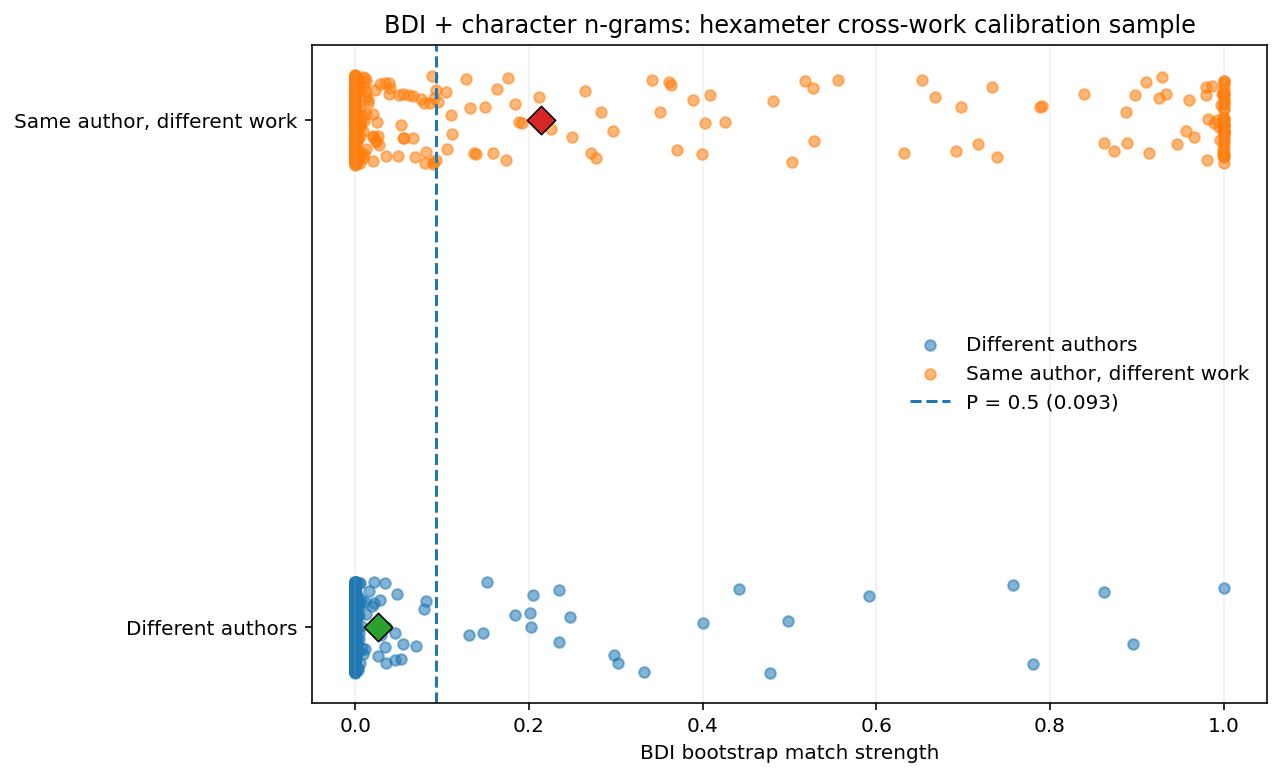

In [25]:
rng_plot = np.random.default_rng(
    42
)

same_scores = (
    valid_calibration.loc[
        valid_calibration["type"]
        == "same",
        "match_strength",
    ]
    .to_numpy()
)

different_scores = (
    valid_calibration.loc[
        valid_calibration["type"]
        == "different",
        "match_strength",
    ]
    .to_numpy()
)

y_same = (
    1
    + rng_plot.uniform(
        -0.09,
        0.09,
        size=len(same_scores),
    )
)

y_different = (
    0
    + rng_plot.uniform(
        -0.09,
        0.09,
        size=len(different_scores),
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    dpi=144,
)

ax.scatter(
    different_scores,
    y_different,
    s=28,
    alpha=0.55,
    label="Different authors",
)

ax.scatter(
    same_scores,
    y_same,
    s=28,
    alpha=0.55,
    label="Same author, different work",
)

if np.isfinite(
    threshold_match
):
    ax.axvline(
        threshold_match,
        linestyle="--",
        linewidth=1.5,
        label=(
            "P = 0.5 "
            f"({threshold_match:.3f})"
        ),
    )

ax.scatter(
    different_scores.mean(),
    0,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.scatter(
    same_scores.mean(),
    1,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.set_yticks([0, 1])

ax.set_yticklabels(
    [
        "Different authors",
        "Same author, different work",
    ]
)

ax.set_xlabel(
    "BDI bootstrap match strength"
)

ax.set_ylabel("")

ax.set_title(
    "BDI + character n-grams: "
    "hexameter cross-work calibration sample"
)

ax.legend(
    frameon=False
)

ax.grid(
    axis="x",
    alpha=0.2,
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_calibration_match_strength.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_calibration_match_strength.pdf",
    bbox_inches="tight",
)

plt.show()

## 12. Saving cross-work configuration

In [27]:
config = {
    "corpus": "hexameters",
    "calibration_design": "cross_work_same_author",
    "sample_tokens": SAMPLE_TOKENS,
    "train_pct": TRAIN_PCT,
    "known_samples": KNOWN_SAMPLES,
    "candidate_tokens_target": (
        KNOWN_SAMPLES * SAMPLE_TOKENS
    ),
    "reference_tokens_target": REFERENCE_TOKENS_TARGET,
    "reference_samples": REFERENCE_SAMPLES,
    "reference_tokens_actual": (
        REFERENCE_SAMPLES * SAMPLE_TOKENS
    ),
    "ngram_range": list(NGRAM_RANGE),
    "max_features": MAX_FEATURES,
    "metric": "minmax",
    "n_bootstrap": N_BOOTSTRAP,
    "rnd_prop": RND_PROP,
    "n_same_author": N_SAME_AUTHOR,
    "n_different_author": N_DIFFERENT_AUTHOR,
    "split_seed": SPLIT_SEED,
    "calibration_seed": CALIBRATION_SEED,
    "same_author_rule": (
        "Q and candidate must come from different works "
        "by the same author"
    ),
    "q_author_population": crosswork_authors,
    "different_author_q_population": crosswork_authors,
    "q_sampling": (
        "uniform eligible author, then uniform work, "
        "then uniform chunk"
    ),
    "explicit_nb_imposters": True,
    "nb_imposters": 0,
    "holdout_files": (
        manifest.loc[
            manifest["holdout"],
            "file",
        ].tolist()
    ),
    "logistic_coefficient": coef,
    "logistic_intercept": intercept,
    "match_strength_at_p_0_5": threshold_match,
}

with open(
    OUTPUT_DIR
    / "bdi_ngram_hexameters_crosswork_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False,
    )

manifest.to_csv(
    OUTPUT_DIR
    / "manifest_snapshot.csv",
    index=False,
)

print("Saved outputs:")

for path in sorted(
    OUTPUT_DIR.iterdir()
):
    print(" -", path.name)

Saved outputs:
 - bdi_ngram_hexameters_crosswork_calibration_match_strength.pdf
 - bdi_ngram_hexameters_crosswork_calibration_match_strength.png
 - bdi_ngram_hexameters_crosswork_calibration_results.csv
 - bdi_ngram_hexameters_crosswork_calibration_results_with_probabilities.csv
 - bdi_ngram_hexameters_crosswork_calibration_specs.csv
 - bdi_ngram_hexameters_crosswork_config.json
 - bdi_ngram_hexameters_crosswork_logistic_regression_model.pkl
 - manifest_snapshot.csv
 - ngrams_hexameters_split_summary.csv
 - ngrams_hexameters_test_chunks.csv
 - ngrams_hexameters_train_chunks.csv


## Outputs to reuse in the corrected application notebook

After running this notebook, the corrected *De ordine mundi* application should use:

- `ngrams_hexameters_test_chunks.csv` from this output directory;
- `bdi_ngram_hexameters_crosswork_logistic_regression_model.pkl`;
- `bdi_ngram_hexameters_crosswork_config.json`.

Before applying it, inspect especially:

- the number of cross-work-eligible authors;
- coefficient and intercept;
- the new P = 0.5 match-strength threshold;
- classification report;
- confusion matrix.

A lower accuracy than the previous calibration is expected if the earlier experiment partly captured work identity.